In [23]:

# ==========================================
# Emotion Classification with Attention
# Step 1: Environment Verification
# ==========================================

import sys
import torch
import numpy as np
import pandas as pd

print("Python Version:", sys.version.split()[0])
print("PyTorch Version:", torch.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

print("\nCUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("WARNING: GPU is not enabled.")

print("\nEnvironment verification completed.")


Python Version: 3.13.16
PyTorch Version: 2.11.0+cu130
NumPy Version: 2.4.6
Pandas Version: 2.2.3

CUDA Available: True
GPU: Tesla T4
CUDA Version: 13.0

Environment verification completed.


In [24]:

# ==========================================
# Step 2: Load and Explore GoEmotions
# ==========================================

try:
    from datasets import load_dataset
except ImportError:
    import subprocess
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "datasets"
    ])
    from datasets import load_dataset

from collections import Counter

# Load the official GoEmotions simplified dataset
dataset = load_dataset(
    "google-research-datasets/go_emotions",
    "simplified"
)

# Display dataset structure
print("Dataset loaded successfully!\n")
print(dataset)

# Display number of examples in each split
print("\nDataset Sizes:")
for split in dataset:
    print(f"{split}: {len(dataset[split]):,} examples")

# Get emotion label names
emotion_names = dataset["train"].features["labels"].feature.names

print("\nNumber of Original Labels:", len(emotion_names))
print("\nOriginal Emotion Labels:")

for i, emotion in enumerate(emotion_names):
    print(f"{i:2d}: {emotion}")

# Explore label distribution in the training split
label_counts = Counter()

for example in dataset["train"]:
    for label_id in example["labels"]:
        label_counts[emotion_names[label_id]] += 1

label_distribution = pd.DataFrame(
    label_counts.most_common(),
    columns=["Emotion", "Count"]
)

print("\nTop 15 Emotions in Training Data:")
display(label_distribution.head(15))

# Check how many emotions each sentence has
labels_per_sentence = Counter(
    len(example["labels"])
    for example in dataset["train"]
)

print("\nNumber of Labels per Sentence:")
for count, frequency in sorted(labels_per_sentence.items()):
    print(f"{count} label(s): {frequency:,} sentences")

# Display sample sentences
print("\nSample Dataset Examples:")
display(
    pd.DataFrame(dataset["train"][:5])
)

print("\nExploration completed.")


Dataset loaded successfully!

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})

Dataset Sizes:
train: 43,410 examples
validation: 5,426 examples
test: 5,427 examples

Number of Original Labels: 28

Original Emotion Labels:
 0: admiration
 1: amusement
 2: anger
 3: annoyance
 4: approval
 5: caring
 6: confusion
 7: curiosity
 8: desire
 9: disappointment
10: disapproval
11: disgust
12: embarrassment
13: excitement
14: fear
15: gratitude
16: grief
17: joy
18: love
19: nervousness
20: optimism
21: pride
22: realization
23: relief
24: remorse
25: sadness
26: surprise
27: neutral

Top 15 Emotions in Training Data:


,Emotion,Count
0,neutral,14219
1,admiration,4130
2,approval,2939
3,gratitude,2662
4,annoyance,2470
5,amusement,2328
6,curiosity,2191
7,love,2086
8,disapproval,2022
9,optimism,1581



Number of Labels per Sentence:
1 label(s): 36,308 sentences
2 label(s): 6,541 sentences
3 label(s): 532 sentences
4 label(s): 28 sentences
5 label(s): 1 sentences

Sample Dataset Examples:


,text,labels,id
0,My favourite food is anything I didn't have to...,[27],eebbqej
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj
3,To make her feel threatened,[14],ed7ypvh
4,Dirty Southern Wankers,[3],ed0bdzj



Exploration completed.


In [25]:

# ==========================================
# Step 3: Emotion Mapping & Dataset Analysis
# ==========================================

# Map original GoEmotions labels to 6 target emotions
emotion_mapping = {
    "admiration": "joy",
    "amusement": "joy",
    "excitement": "joy",
    "gratitude": "joy",
    "joy": "joy",
    "love": "joy",
    "optimism": "joy",
    "pride": "joy",
    "relief": "joy",

    "disappointment": "sadness",
    "grief": "sadness",
    "remorse": "sadness",
    "sadness": "sadness",

    "anger": "anger",
    "annoyance": "anger",
    "disapproval": "anger",

    "fear": "fear",
    "nervousness": "fear",

    "surprise": "surprise",

    "disgust": "disgust"
}

target_emotions = [
    "joy",
    "sadness",
    "anger",
    "fear",
    "surprise",
    "disgust"
]

# Convert original labels into target labels
def map_emotions(original_label_ids):
    original_labels = [
        emotion_names[label_id]
        for label_id in original_label_ids
    ]

    mapped_labels = {
        emotion_mapping[label]
        for label in original_labels
        if label in emotion_mapping
    }

    # Keep only examples with exactly one target emotion
    if len(mapped_labels) == 1:
        return list(mapped_labels)[0]

    # Exclude neutral, unmapped, or ambiguous examples
    return None


# Analyze each existing split without changing its boundaries
mapped_dataset_stats = {}

for split in dataset:
    total_examples = len(dataset[split])
    retained_examples = 0
    excluded_examples = 0
    mapped_counts = Counter()
    ambiguous_examples = []

    for example in dataset[split]:
        mapped_label = map_emotions(example["labels"])

        if mapped_label is not None:
            retained_examples += 1
            mapped_counts[mapped_label] += 1
        else:
            excluded_examples += 1

            original_labels = [
                emotion_names[label_id]
                for label_id in example["labels"]
            ]

            mapped_targets = {
                emotion_mapping[label]
                for label in original_labels
                if label in emotion_mapping
            }

            if len(mapped_targets) > 1:
                ambiguous_examples.append({
                    "text": example["text"],
                    "original_labels": original_labels,
                    "mapped_targets": sorted(mapped_targets)
                })

    mapped_dataset_stats[split] = {
        "total": total_examples,
        "retained": retained_examples,
        "excluded": excluded_examples,
        "class_counts": mapped_counts,
        "ambiguous": ambiguous_examples
    }


# Display retained and excluded examples
summary_rows = []

for split, stats in mapped_dataset_stats.items():
    summary_rows.append({
        "Split": split,
        "Original Examples": stats["total"],
        "Retained Examples": stats["retained"],
        "Excluded Examples": stats["excluded"],
        "Retention Rate (%)": round(
            100 * stats["retained"] / stats["total"], 2
        )
    })

print("Dataset Mapping Summary:")
display(pd.DataFrame(summary_rows))


# Display class distribution for each split
distribution_rows = []

for split, stats in mapped_dataset_stats.items():
    for emotion in target_emotions:
        distribution_rows.append({
            "Split": split,
            "Emotion": emotion,
            "Count": stats["class_counts"].get(emotion, 0)
        })

print("\nMapped Emotion Distribution:")
display(pd.DataFrame(distribution_rows))


# Show ambiguous examples for manual inspection
ambiguous_samples = []

for split, stats in mapped_dataset_stats.items():
    for example in stats["ambiguous"][:3]:
        ambiguous_samples.append({
            "Split": split,
            "Text": example["text"],
            "Original Labels": example["original_labels"],
            "Mapped Targets": example["mapped_targets"]
        })

print("\nExamples Excluded Due to Conflicting Emotions:")
if ambiguous_samples:
    display(pd.DataFrame(ambiguous_samples))
else:
    print("No conflicting examples found.")


print("\nMapping analysis completed.")


Dataset Mapping Summary:


,Split,Original Examples,Retained Examples,Excluded Examples,Retention Rate (%)
0,train,43410,22386,21024,51.57
1,validation,5426,2766,2660,50.98
2,test,5427,2781,2646,51.24



Mapped Emotion Distribution:


,Split,Emotion,Count
0,train,joy,13020
1,train,sadness,2454
2,train,anger,4879
3,train,fear,615
4,train,surprise,857
5,train,disgust,561
6,validation,joy,1608
7,validation,sadness,283
8,validation,anger,621
9,validation,fear,84



Examples Excluded Due to Conflicting Emotions:


,Split,Text,Original Labels,Mapped Targets
0,train,2019 should just be a picture of a trash can o...,"[annoyance, disappointment, surprise]","[anger, sadness, surprise]"
1,train,"Oh wow. Yeah I’m very new, only about 8 hours ...","[admiration, surprise]","[joy, surprise]"
2,train,wow so almost every sub has grown a lot in 7 m...,"[amusement, surprise]","[joy, surprise]"
3,validation,Lol dream on buddy. You’ve had enough attentio...,"[amusement, annoyance, sadness]","[anger, joy, sadness]"
4,validation,I am confused. I don't understand how that rel...,"[amusement, confusion, curiosity, remorse]","[joy, sadness]"
5,validation,"Hahahah thank you so much, username does not c...","[amusement, disapproval, gratitude]","[anger, joy]"
6,test,A surprise turn of events! I'm so glad you hea...,"[joy, surprise]","[joy, surprise]"
7,test,Man I hate double standards. I love the show b...,"[disapproval, love]","[anger, joy]"
8,test,[NAME] stopped napping at 18 months. We’ve bee...,"[admiration, surprise]","[joy, surprise]"



Mapping analysis completed.


In [26]:

# ==========================================
# Step 4: Build the Final 6-Class Dataset
# ==========================================

from datasets import Dataset, DatasetDict

# Fixed label order for all models
label2id = {
    emotion: idx
    for idx, emotion in enumerate(target_emotions)
}

id2label = {
    idx: emotion
    for emotion, idx in label2id.items()
}

# Build the final dataset using the approved mapping
final_data = {}

for split in dataset:
    texts = []
    labels = []
    ids = []

    for example in dataset[split]:
        mapped_label = map_emotions(example["labels"])

        if mapped_label is not None:
            texts.append(example["text"])
            labels.append(label2id[mapped_label])
            ids.append(example["id"])

    final_data[split] = Dataset.from_dict({
        "text": texts,
        "label": labels,
        "id": ids
    })

final_dataset = DatasetDict(final_data)

# Verify the final dataset
print("Final Dataset:")
print(final_dataset)

print("\nLabel Mapping:")
for label_id, emotion in id2label.items():
    print(f"{label_id}: {emotion}")

# Verify class counts
for split in final_dataset:
    counts = Counter(final_dataset[split]["label"])

    print(f"\n{split.upper()} Distribution:")
    for label_id, emotion in id2label.items():
        print(f"{emotion:10s}: {counts.get(label_id, 0):,}")

# Sanity checks
assert len(final_dataset["train"]) == 22386
assert len(final_dataset["validation"]) == 2766
assert len(final_dataset["test"]) == 2781

assert set(final_dataset["train"]["label"]) == set(range(6))
assert set(final_dataset["validation"]["label"]) == set(range(6))
assert set(final_dataset["test"]["label"]) == set(range(6))

print("\nAll dataset checks passed!")


Final Dataset:
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 22386
    })
    validation: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 2766
    })
    test: Dataset({
        features: ['text', 'label', 'id'],
        num_rows: 2781
    })
})

Label Mapping:
0: joy
1: sadness
2: anger
3: fear
4: surprise
5: disgust

TRAIN Distribution:
joy       : 13,020
sadness   : 2,454
anger     : 4,879
fear      : 615
surprise  : 857
disgust   : 561

VALIDATION Distribution:
joy       : 1,608
sadness   : 283
anger     : 621
fear      : 84
surprise  : 104
disgust   : 66

TEST Distribution:
joy       : 1,570
sadness   : 287
anger     : 646
fear      : 86
surprise  : 110
disgust   : 82

All dataset checks passed!


In [28]:

# ==========================================
# Step 5: Final Text Preprocessing
# ==========================================

import re
import numpy as np

# Improved tokenizer: preserve contractions, punctuation and emojis
def tokenize_text(text):
    text = text.lower().strip()

    tokens = re.findall(
        r"[:;=8][-^']?[)(/DPp]|<3|\w+(?:['’]\w+)*|[^\w\s]",
        text,
        flags=re.UNICODE
    )

    return tokens


# Fixed maximum sequence length
MAX_SEQ_LEN = 40

# Tokenize all splits
tokenized_data = {
    split: [
        tokenize_text(text)
        for text in final_dataset[split]["text"]
    ]
    for split in final_dataset
}

# Analyze sequence lengths
train_lengths = np.array([
    len(tokens)
    for tokens in tokenized_data["train"]
])

print("Final Tokenization Statistics")
print("--------------------------------")
print("Maximum sequence length:", train_lengths.max())
print("Mean sequence length:", round(train_lengths.mean(), 2))
print("Selected MAX_SEQ_LEN:", MAX_SEQ_LEN)

print("\nTruncation Analysis:")

for split, sequences in tokenized_data.items():
    truncated = sum(
        len(tokens) > MAX_SEQ_LEN
        for tokens in sequences
    )

    print(
        f"{split}: {truncated:,} / {len(sequences):,} "
        f"({truncated / len(sequences) * 100:.2f}%)"
    )

# Verify contractions and emoticons
test_texts = [
    "I can't believe this!",
    "I'm so happy :)",
    "This is terrible 😢"
]

print("\nTokenizer Verification:")

for text in test_texts:
    print(text, "->", tokenize_text(text))

print("\nFinal Tokenization completed successfully!")


Final Tokenization Statistics
--------------------------------
Maximum sequence length: 46
Mean sequence length: 15.12
Selected MAX_SEQ_LEN: 40

Truncation Analysis:
train: 2 / 22,386 (0.01%)
validation: 1 / 2,766 (0.04%)
test: 0 / 2,781 (0.00%)

Tokenizer Verification:
I can't believe this! -> ['i', "can't", 'believe', 'this', '!']
I'm so happy :) -> ["i'm", 'so', 'happy', ':)']
This is terrible 😢 -> ['this', 'is', 'terrible', '😢']

Final Tokenization completed successfully!


In [29]:

# ==========================================
# Step 6: Build Vocabulary
# ==========================================

from collections import Counter

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

# Build vocabulary from training data ONLY
word_counts = Counter(
    token
    for sentence in tokenized_data["train"]
    for token in sentence
)

# Special tokens
vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

# Add words ordered by frequency
for word, count in word_counts.most_common():
    if word not in vocab:
        vocab[word] = len(vocab)

# Reverse vocabulary
id2word = {
    idx: word
    for word, idx in vocab.items()
}

VOCAB_SIZE = len(vocab)

# Calculate vocabulary statistics
total_tokens = sum(word_counts.values())
unique_tokens = len(word_counts)

print("Vocabulary Building Results")
print("--------------------------------")
print("Total training tokens:", f"{total_tokens:,}")
print("Unique training words:", f"{unique_tokens:,}")
print("Vocabulary size:", f"{VOCAB_SIZE:,}")
print("Minimum word frequency:", min(word_counts.values()))

# Most frequent words
print("\nTop 20 Most Frequent Words:")
display(pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
))

# Verify special tokens
print("\nSpecial Tokens:")
print("PAD:", vocab[PAD_TOKEN])
print("UNK:", vocab[UNK_TOKEN])

# Test vocabulary encoding
sample_tokens = tokenized_data["train"][0]

sample_ids = [
    vocab.get(token, vocab[UNK_TOKEN])
    for token in sample_tokens
]

print("\nVocabulary Encoding Example:")
print("Tokens:", sample_tokens)
print("IDs:", sample_ids)

# Verify no validation/test words were used to build vocabulary
assert vocab[PAD_TOKEN] == 0
assert vocab[UNK_TOKEN] == 1
assert len(vocab) == len(id2word)

print("\nVocabulary checks passed!")


Vocabulary Building Results
--------------------------------
Total training tokens: 338,458
Unique training words: 18,308
Vocabulary size: 18,310
Minimum word frequency: 1

Top 20 Most Frequent Words:


,Word,Frequency
0,.,24728
1,i,9341
2,the,8759
3,",",7482
4,a,6293
5,to,6160
6,!,5891
7,you,5276
8,and,4535
9,is,4294



Special Tokens:
PAD: 0
UNK: 1

Vocabulary Encoding Example:
Tokens: ['why', 'the', 'fuck', 'is', 'bayless', 'isoing']
IDs: [128, 4, 147, 11, 6150, 8739]

Vocabulary checks passed!


In [30]:

# ==========================================
# Step 7: GloVe 100D Pre-trained Embeddings
# ==========================================

import subprocess
import sys

# Install Gensim if needed
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "gensim"
])

import gensim.downloader as api

# Download pre-trained GloVe embeddings
print("Downloading GloVe 100D embeddings...")

glove = api.load("glove-wiki-gigaword-100")

EMBEDDING_DIM = 100

print("\nGloVe loaded successfully!")
print("Embedding dimension:", EMBEDDING_DIM)

# Create embedding matrix
embedding_matrix = np.random.normal(
    loc=0.0,
    scale=0.05,
    size=(VOCAB_SIZE, EMBEDDING_DIM)
).astype(np.float32)

# PAD vector must be zero
embedding_matrix[vocab[PAD_TOKEN]] = np.zeros(
    EMBEDDING_DIM, dtype=np.float32
)

# Match vocabulary words with GloVe vectors
found_words = 0
found_tokens = 0
total_tokens = 0

for word, word_id in vocab.items():

    if word in [PAD_TOKEN, UNK_TOKEN]:
        continue

    frequency = word_counts[word]
    total_tokens += frequency

    if word in glove:
        embedding_matrix[word_id] = glove[word]
        found_words += 1
        found_tokens += frequency

# Calculate coverage
unique_words = len(word_counts)

unique_coverage = found_words / unique_words * 100
token_coverage = found_tokens / total_tokens * 100

print("\nGloVe Coverage Results")
print("--------------------------------")
print(f"Vocabulary words found: {found_words:,}/{unique_words:,}")
print(f"Unique word coverage: {unique_coverage:.2f}%")
print(f"Token coverage: {token_coverage:.2f}%")

print("\nEmbedding Matrix:")
print("Shape:", embedding_matrix.shape)
print("Data type:", embedding_matrix.dtype)

# Verify embedding matrix
assert embedding_matrix.shape == (
    VOCAB_SIZE, EMBEDDING_DIM
)

assert np.all(embedding_matrix[vocab[PAD_TOKEN]] == 0)
assert np.isfinite(embedding_matrix).all()

print("\nEmbedding verification passed!")



GloVe loaded successfully!
Embedding dimension: 100

GloVe Coverage Results
--------------------------------
Vocabulary words found: 15,819/18,308
Unique word coverage: 86.40%
Token coverage: 95.56%

Embedding Matrix:
Shape: (18310, 100)
Data type: float32

Embedding verification passed!


In [31]:

# ==========================================
# Step 8: Padding & PyTorch DataLoaders
# ==========================================

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 64

# Convert tokenized sentences into fixed-length ID sequences
def encode_and_pad(tokens):
    token_ids = [
        vocab.get(token, vocab[UNK_TOKEN])
        for token in tokens[:MAX_SEQ_LEN]
    ]

    padding_length = MAX_SEQ_LEN - len(token_ids)

    token_ids += [vocab[PAD_TOKEN]] * padding_length

    return token_ids


# Prepare all splits
encoded_data = {}

for split in final_dataset:
    encoded_data[split] = {
        "input_ids": torch.tensor(
            [
                encode_and_pad(tokens)
                for tokens in tokenized_data[split]
            ],
            dtype=torch.long
        ),
        "labels": torch.tensor(
            final_dataset[split]["label"],
            dtype=torch.long
        )
    }


# Custom PyTorch Dataset
class EmotionDataset(Dataset):

    def __init__(self, input_ids, labels):
        self.input_ids = input_ids
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": self.input_ids[index],
            "labels": self.labels[index]
        }


# Create PyTorch datasets
pytorch_datasets = {
    split: EmotionDataset(
        encoded_data[split]["input_ids"],
        encoded_data[split]["labels"]
    )
    for split in encoded_data
}


# Create DataLoaders
dataloaders = {
    split: DataLoader(
        pytorch_datasets[split],
        batch_size=BATCH_SIZE,
        shuffle=(split == "train"),
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    for split in pytorch_datasets
}


# Calculate class weights using TRAINING data only
train_labels = encoded_data["train"]["labels"].numpy()

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(target_emotions)),
    y=train_labels
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

# Normalize weights to have an average of 1
class_weights = class_weights / class_weights.mean()


# Verify the prepared data
print("PyTorch Data Preparation")
print("--------------------------------")
print("Device:", DEVICE)
print("Batch Size:", BATCH_SIZE)
print("Maximum Sequence Length:", MAX_SEQ_LEN)

for split in encoded_data:
    print(f"\n{split.upper()}:")
    print("Input shape:", encoded_data[split]["input_ids"].shape)
    print("Labels shape:", encoded_data[split]["labels"].shape)
    print("Number of batches:", len(dataloaders[split]))

print("\nClass Weights:")
for emotion, weight in zip(target_emotions, class_weights):
    print(f"{emotion:10s}: {weight.item():.4f}")

# Inspect one batch
sample_batch = next(iter(dataloaders["train"]))

print("\nSample Batch:")
print("Input IDs:", sample_batch["input_ids"].shape)
print("Labels:", sample_batch["labels"].shape)

# Sanity checks
assert sample_batch["input_ids"].shape == (
    BATCH_SIZE, MAX_SEQ_LEN
)

assert sample_batch["labels"].shape == (BATCH_SIZE,)

assert torch.all(
    encoded_data["train"]["input_ids"] >= 0
)

assert torch.all(
    encoded_data["train"]["input_ids"] < VOCAB_SIZE
)

assert torch.all(
    encoded_data["train"]["input_ids"][:, 0] != vocab[PAD_TOKEN]
)

assert torch.all(
    class_weights > 0
)

print("\nAll PyTorch data checks passed!")


PyTorch Data Preparation
--------------------------------
Device: cuda
Batch Size: 64
Maximum Sequence Length: 40

TRAIN:
Input shape: torch.Size([22386, 40])
Labels shape: torch.Size([22386])
Number of batches: 350

VALIDATION:
Input shape: torch.Size([2766, 40])
Labels shape: torch.Size([2766])
Number of batches: 44

TEST:
Input shape: torch.Size([2781, 40])
Labels shape: torch.Size([2781])
Number of batches: 44

Class Weights:
joy       : 0.0875
sadness   : 0.4644
anger     : 0.2336
fear      : 1.8531
surprise  : 1.3298
disgust   : 2.0315

Sample Batch:
Input IDs: torch.Size([64, 40])
Labels: torch.Size([64])

All PyTorch data checks passed!


In [32]:

# ==========================================
# Step 9: LSTM Model Architecture
# ==========================================

import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

# Model configuration
EMBEDDING_DIM = 100
HIDDEN_DIM = 128
NUM_LAYERS = 2
NUM_CLASSES = len(target_emotions)
DROPOUT = 0.3


class LSTMEmotionClassifier(nn.Module):

    def __init__(
        self,
        embedding_matrix,
        hidden_dim=HIDDEN_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
        num_classes=NUM_CLASSES
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_matrix.shape

        # Pre-trained GloVe embedding layer
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=False,
            padding_idx=vocab[PAD_TOKEN]
        )

        # Two-layer LSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        # Classification layer
        self.classifier = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, input_ids):

        # Calculate actual sequence lengths
        lengths = (input_ids != vocab[PAD_TOKEN]).sum(dim=1)

        embedded = self.embedding(input_ids)

        # Ignore padded positions during recurrent processing
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, cell) = self.lstm(packed)

        # Final hidden state of the last LSTM layer
        final_hidden = hidden[-1]

        output = self.dropout(final_hidden)

        logits = self.classifier(output)

        return logits


# Initialize the LSTM model
lstm_model = LSTMEmotionClassifier(
    embedding_matrix=embedding_matrix
).to(DEVICE)

# Weighted Cross Entropy Loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE)
)

# Adam optimizer
optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

# Count trainable parameters
trainable_parameters = sum(
    parameter.numel()
    for parameter in lstm_model.parameters()
    if parameter.requires_grad
)

# Test forward pass
sample_batch = next(iter(dataloaders["train"]))
sample_input = sample_batch["input_ids"].to(DEVICE)

with torch.no_grad():
    sample_output = lstm_model(sample_input)

print("LSTM Architecture Verification")
print("--------------------------------")
print("Device:", DEVICE)
print("Embedding Dimension:", EMBEDDING_DIM)
print("Hidden Dimension:", HIDDEN_DIM)
print("LSTM Layers:", NUM_LAYERS)
print("Dropout:", DROPOUT)
print("Number of Classes:", NUM_CLASSES)
print("Trainable Parameters:", f"{trainable_parameters:,}")
print("Input Shape:", sample_input.shape)
print("Output Shape:", sample_output.shape)

assert sample_output.shape == (BATCH_SIZE, NUM_CLASSES)
assert torch.isfinite(sample_output).all()

print("\nLSTM model initialized successfully!")


LSTM Architecture Verification
--------------------------------
Device: cuda
Embedding Dimension: 100
Hidden Dimension: 128
LSTM Layers: 2
Dropout: 0.3
Number of Classes: 6
Trainable Parameters: 2,081,630
Input Shape: torch.Size([64, 40])
Output Shape: torch.Size([64, 6])

LSTM model initialized successfully!


In [33]:

import os
import copy
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score

CHECKPOINT_DIR = "/content/emotion_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def get_logits(model, input_ids):
    output = model(input_ids)
    # Supports models that return (logits, attention_weights)
    if isinstance(output, tuple):
        return output[0]
    return output


def train_emotion_model(
    model,
    model_name,
    epochs=15,
    patience=3,
    learning_rate=0.001
):
    criterion = nn.CrossEntropyLoss(
        weight=class_weights.to(DEVICE)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_val_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    best_state = None

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": []
    }

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{model_name}_best.pt"
    )

    print(f"Training: {model_name}")
    print("=" * 60)

    for epoch in range(1, epochs + 1):

        # -------------------------
        # Training
        # -------------------------
        model.train()

        train_losses = []
        train_predictions = []
        train_targets = []

        for batch in dataloaders["train"]:
            input_ids = batch["input_ids"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = get_logits(model, input_ids)
            loss = criterion(logits, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            train_losses.append(loss.item())
            train_predictions.extend(
                logits.argmax(dim=1).detach().cpu().numpy()
            )
            train_targets.extend(labels.detach().cpu().numpy())

        train_loss = float(np.mean(train_losses))
        train_accuracy = accuracy_score(
            train_targets, train_predictions
        )

        # -------------------------
        # Validation
        # -------------------------
        model.eval()

        val_losses = []
        val_predictions = []
        val_targets = []

        with torch.no_grad():
            for batch in dataloaders["validation"]:
                input_ids = batch["input_ids"].to(DEVICE)
                labels = batch["labels"].to(DEVICE)

                logits = get_logits(model, input_ids)
                loss = criterion(logits, labels)

                val_losses.append(loss.item())
                val_predictions.extend(
                    logits.argmax(dim=1).cpu().numpy()
                )
                val_targets.extend(labels.cpu().numpy())

        val_loss = float(np.mean(val_losses))
        val_accuracy = accuracy_score(
            val_targets, val_predictions
        )
        val_macro_f1 = f1_score(
            val_targets,
            val_predictions,
            average="macro",
            zero_division=0
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["val_macro_f1"].append(val_macro_f1)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f} | "
            f"Val Macro F1: {val_macro_f1:.4f}"
        )

        # -------------------------
        # Save best checkpoint
        # -------------------------
        if val_macro_f1 > best_val_f1:
            best_val_f1 = val_macro_f1
            best_epoch = epoch
            epochs_without_improvement = 0

            best_state = copy.deepcopy(model.state_dict())

            torch.save(
                {
                    "model_state_dict": best_state,
                    "model_name": model_name,
                    "best_epoch": best_epoch,
                    "best_val_macro_f1": best_val_f1
                },
                checkpoint_path
            )

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(
                f"\nEarly stopping triggered at epoch {epoch}."
            )
            break

    # Restore best validation checkpoint
    if best_state is not None:
        model.load_state_dict(best_state)

    print("\n" + "=" * 60)
    print(f"{model_name} training completed.")
    print(f"Best Epoch: {best_epoch}")
    print(f"Best Validation Macro F1: {best_val_f1:.4f}")
    print(f"Checkpoint: {checkpoint_path}")

    return model, history


In [34]:
lstm_model, lstm_history = train_emotion_model(
    model=lstm_model,
    model_name="LSTM",
    epochs=15,
    patience=3,
    learning_rate=0.001
)

Training: LSTM
Epoch 01/15 | Train Loss: 1.5063 | Train Acc: 0.5201 | Val Loss: 1.1997 | Val Acc: 0.7007 | Val Macro F1: 0.5193
Epoch 02/15 | Train Loss: 0.9425 | Train Acc: 0.7354 | Val Loss: 0.9179 | Val Acc: 0.6837 | Val Macro F1: 0.5831
Epoch 03/15 | Train Loss: 0.6988 | Train Acc: 0.7988 | Val Loss: 0.8312 | Val Acc: 0.7762 | Val Macro F1: 0.6308
Epoch 04/15 | Train Loss: 0.5351 | Train Acc: 0.8403 | Val Loss: 0.8999 | Val Acc: 0.7726 | Val Macro F1: 0.6388
Epoch 05/15 | Train Loss: 0.4155 | Train Acc: 0.8681 | Val Loss: 0.9525 | Val Acc: 0.7892 | Val Macro F1: 0.6715
Epoch 06/15 | Train Loss: 0.3112 | Train Acc: 0.8969 | Val Loss: 1.1400 | Val Acc: 0.7939 | Val Macro F1: 0.6696
Epoch 07/15 | Train Loss: 0.2395 | Train Acc: 0.9190 | Val Loss: 1.2669 | Val Acc: 0.7802 | Val Macro F1: 0.6609
Epoch 08/15 | Train Loss: 0.1767 | Train Acc: 0.9363 | Val Loss: 1.3677 | Val Acc: 0.7708 | Val Macro F1: 0.6421

Early stopping triggered at epoch 8.

LSTM training completed.
Best Epoch: 5
Bes

In [35]:
class GRUEmotionClassifier(nn.Module):
    def __init__(
        self,
        embedding_matrix,
        hidden_dim=HIDDEN_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
        num_classes=NUM_CLASSES
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=False,
            padding_idx=vocab[PAD_TOKEN]
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids):
        lengths = (input_ids != vocab[PAD_TOKEN]).sum(dim=1)

        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(packed)

        final_hidden = hidden[-1]
        output = self.dropout(final_hidden)
        logits = self.classifier(output)

        return logits


gru_model = GRUEmotionClassifier(
    embedding_matrix=embedding_matrix
).to(DEVICE)

sample_batch = next(iter(dataloaders["train"]))
sample_input = sample_batch["input_ids"].to(DEVICE)

with torch.no_grad():
    sample_output = gru_model(sample_input)

trainable_parameters = sum(
    p.numel() for p in gru_model.parameters()
    if p.requires_grad
)

print("GRU Architecture Verification")
print("-" * 40)
print(f"Device: {DEVICE}")
print(f"Embedding Dimension: {EMBEDDING_DIM}")
print(f"Hidden Dimension: {HIDDEN_DIM}")
print(f"GRU Layers: {NUM_LAYERS}")
print(f"Dropout: {DROPOUT}")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"Trainable Parameters: {trainable_parameters:,}")
print(f"Input Shape: {sample_input.shape}")
print(f"Output Shape: {sample_output.shape}")

assert sample_output.shape == (sample_input.shape[0], NUM_CLASSES)
assert torch.isfinite(sample_output).all()

print("\nGRU model initialized successfully!")

GRU Architecture Verification
----------------------------------------
Device: cuda
Embedding Dimension: 100
Hidden Dimension: 128
GRU Layers: 2
Dropout: 0.3
Number of Classes: 6
Trainable Parameters: 2,019,166
Input Shape: torch.Size([64, 40])
Output Shape: torch.Size([64, 6])

GRU model initialized successfully!


In [36]:
gru_model, gru_history = train_emotion_model(
    model=gru_model,
    model_name="GRU",
    epochs=15,
    patience=3,
    learning_rate=0.001
)

Training: GRU
Epoch 01/15 | Train Loss: 1.3862 | Train Acc: 0.5498 | Val Loss: 0.9244 | Val Acc: 0.6909 | Val Macro F1: 0.5612
Epoch 02/15 | Train Loss: 0.7923 | Train Acc: 0.7622 | Val Loss: 0.8160 | Val Acc: 0.8040 | Val Macro F1: 0.6787
Epoch 03/15 | Train Loss: 0.5913 | Train Acc: 0.8151 | Val Loss: 0.8309 | Val Acc: 0.7878 | Val Macro F1: 0.6746
Epoch 04/15 | Train Loss: 0.4471 | Train Acc: 0.8533 | Val Loss: 0.8583 | Val Acc: 0.7849 | Val Macro F1: 0.6536
Epoch 05/15 | Train Loss: 0.3216 | Train Acc: 0.8863 | Val Loss: 1.0259 | Val Acc: 0.7834 | Val Macro F1: 0.6561

Early stopping triggered at epoch 5.

GRU training completed.
Best Epoch: 2
Best Validation Macro F1: 0.6787
Checkpoint: /content/emotion_checkpoints/GRU_best.pt


In [37]:
from torch.nn.utils.rnn import pad_packed_sequence

class BiLSTMAttentionClassifier(nn.Module):
    def __init__(
        self,
        embedding_matrix,
        hidden_dim=HIDDEN_DIM,
        num_layers=NUM_LAYERS,
        dropout=DROPOUT,
        num_classes=NUM_CLASSES
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_matrix.shape

        self.pad_idx = vocab[PAD_TOKEN]

        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=False,
            padding_idx=self.pad_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.attention = nn.Linear(hidden_dim * 2, 1)

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward_with_attention(self, input_ids):
        mask = input_ids != self.pad_idx
        lengths = mask.sum(dim=1)

        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, _ = self.lstm(packed)

        lstm_output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=input_ids.size(1)
        )

        attention_scores = self.attention(lstm_output).squeeze(-1)

        attention_scores = attention_scores.masked_fill(
            ~mask,
            -1e9
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        context = torch.sum(
            lstm_output * attention_weights.unsqueeze(-1),
            dim=1
        )

        context = self.dropout(context)

        logits = self.classifier(context)

        return logits, attention_weights

    def forward(self, input_ids):
        logits, _ = self.forward_with_attention(input_ids)
        return logits


bilstm_attention_model = BiLSTMAttentionClassifier(
    embedding_matrix=embedding_matrix
).to(DEVICE)

sample_batch = next(iter(dataloaders["train"]))
sample_input = sample_batch["input_ids"].to(DEVICE)

with torch.no_grad():
    sample_output, sample_attention = (
        bilstm_attention_model.forward_with_attention(sample_input)
    )

trainable_parameters = sum(
    p.numel()
    for p in bilstm_attention_model.parameters()
    if p.requires_grad
)

print("BiLSTM + Attention Architecture Verification")
print("-" * 50)
print(f"Device: {DEVICE}")
print(f"Embedding Dimension: {EMBEDDING_DIM}")
print(f"Hidden Dimension: {HIDDEN_DIM}")
print(f"Bidirectional: True")
print(f"LSTM Layers: {NUM_LAYERS}")
print(f"Dropout: {DROPOUT}")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"Trainable Parameters: {trainable_parameters:,}")
print(f"Input Shape: {sample_input.shape}")
print(f"Output Shape: {sample_output.shape}")
print(f"Attention Shape: {sample_attention.shape}")

assert sample_output.shape == (sample_input.shape[0], NUM_CLASSES)
assert sample_attention.shape == sample_input.shape
assert torch.isfinite(sample_output).all()
assert torch.isfinite(sample_attention).all()

# Verify attention weights sum to 1
attention_sums = sample_attention.sum(dim=1)
assert torch.allclose(
    attention_sums,
    torch.ones_like(attention_sums),
    atol=1e-5
)

# Verify padding tokens receive zero attention
padding_attention = sample_attention[
    sample_input == vocab[PAD_TOKEN]
]
assert torch.allclose(
    padding_attention,
    torch.zeros_like(padding_attention),
    atol=1e-7
)

print("\nAttention verification passed!")
print("BiLSTM + Attention model initialized successfully!")

BiLSTM + Attention Architecture Verification
--------------------------------------------------
Device: cuda
Embedding Dimension: 100
Hidden Dimension: 128
Bidirectional: True
LSTM Layers: 2
Dropout: 0.3
Number of Classes: 6
Trainable Parameters: 2,463,583
Input Shape: torch.Size([64, 40])
Output Shape: torch.Size([64, 6])
Attention Shape: torch.Size([64, 40])

Attention verification passed!
BiLSTM + Attention model initialized successfully!


In [38]:
bilstm_attention_model, attention_history = train_emotion_model(
    model=bilstm_attention_model,
    model_name="BiLSTM_Attention",
    epochs=15,
    patience=3,
    learning_rate=0.001
)

Training: BiLSTM_Attention
Epoch 01/15 | Train Loss: 1.3289 | Train Acc: 0.5628 | Val Loss: 0.9051 | Val Acc: 0.7321 | Val Macro F1: 0.6061
Epoch 02/15 | Train Loss: 0.7596 | Train Acc: 0.7691 | Val Loss: 0.7430 | Val Acc: 0.7661 | Val Macro F1: 0.6341
Epoch 03/15 | Train Loss: 0.5821 | Train Acc: 0.8154 | Val Loss: 0.7616 | Val Acc: 0.7531 | Val Macro F1: 0.6324
Epoch 04/15 | Train Loss: 0.4620 | Train Acc: 0.8481 | Val Loss: 0.8237 | Val Acc: 0.7874 | Val Macro F1: 0.6653
Epoch 05/15 | Train Loss: 0.3499 | Train Acc: 0.8769 | Val Loss: 0.9973 | Val Acc: 0.7975 | Val Macro F1: 0.6767
Epoch 06/15 | Train Loss: 0.2536 | Train Acc: 0.9072 | Val Loss: 1.1049 | Val Acc: 0.7903 | Val Macro F1: 0.6811
Epoch 07/15 | Train Loss: 0.1826 | Train Acc: 0.9288 | Val Loss: 1.2974 | Val Acc: 0.7993 | Val Macro F1: 0.6799
Epoch 08/15 | Train Loss: 0.1352 | Train Acc: 0.9464 | Val Loss: 1.4037 | Val Acc: 0.7863 | Val Macro F1: 0.6619
Epoch 09/15 | Train Loss: 0.0976 | Train Acc: 0.9585 | Val Loss: 1.91

In [40]:
# Keep only the inputs required by DistilBERT
for split in tokenized_transformer_dataset:
    if "token_type_ids" in tokenized_transformer_dataset[split].column_names:
        tokenized_transformer_dataset[split] = (
            tokenized_transformer_dataset[split].remove_columns(
                "token_type_ids"
            )
        )

# Final verification
required_columns = {
    "input_ids",
    "attention_mask",
    "label"
}

for split in tokenized_transformer_dataset:
    assert required_columns.issubset(
        set(tokenized_transformer_dataset[split].column_names)
    )

    assert len(tokenized_transformer_dataset[split]) == len(final_dataset[split])

sample = tokenized_transformer_dataset["train"][0]

assert len(sample["input_ids"]) == len(sample["attention_mask"])
assert len(sample["input_ids"]) <= TRANSFORMER_MAX_LENGTH

print("DistilBERT dataset verification passed!")
print("-" * 45)

for split in tokenized_transformer_dataset:
    print(
        f"{split.capitalize()}: "
        f"{len(tokenized_transformer_dataset[split]):,} samples"
    )

print("\nFinal columns:", tokenized_transformer_dataset["train"].column_names)
print("Tokenization pipeline is ready!")

DistilBERT dataset verification passed!
---------------------------------------------
Train: 22,386 samples
Validation: 2,766 samples
Test: 2,781 samples

Final columns: ['label', 'input_ids', 'attention_mask']
Tokenization pipeline is ready!


In [42]:
import inspect
from transformers import TrainingArguments, Trainer

print("TrainingArguments supported parameters:")
print(inspect.signature(TrainingArguments.__init__))

print("\nTrainer compute_loss signature:")
print(inspect.signature(Trainer.compute_loss))

TrainingArguments supported parameters:
(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 5e-05, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool = False, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = False, gradient_checkpointing_kwargs: dict[str, typing.Any] | str | None = Non

In [43]:
import math

# -----------------------------------
# 1. Calculate Warmup Steps
# -----------------------------------

BERT_EPOCHS = 5
BERT_BATCH_SIZE = 16

steps_per_epoch = math.ceil(
    len(tokenized_transformer_dataset["train"]) / BERT_BATCH_SIZE
)

total_training_steps = steps_per_epoch * BERT_EPOCHS
warmup_steps = int(total_training_steps * 0.10)


# -----------------------------------
# 2. Training Configuration
# -----------------------------------

training_args = TrainingArguments(
    output_dir="/content/emotion_checkpoints/DistilBERT",

    num_train_epochs=BERT_EPOCHS,

    per_device_train_batch_size=BERT_BATCH_SIZE,
    per_device_eval_batch_size=32,

    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=warmup_steps,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,

    save_total_limit=2,

    fp16=torch.cuda.is_available(),

    logging_strategy="steps",
    logging_steps=100,

    report_to="none",

    seed=42,
    data_seed=42,

    dataloader_num_workers=0
)


# -----------------------------------
# 3. Initialize Weighted Trainer
# -----------------------------------

bert_trainer = WeightedEmotionTrainer(
    model=bert_model,
    args=training_args,

    train_dataset=tokenized_transformer_dataset["train"],
    eval_dataset=tokenized_transformer_dataset["validation"],

    data_collator=data_collator,
    processing_class=transformer_tokenizer,

    compute_metrics=compute_transformer_metrics,

    class_weights=class_weights
)

bert_trainer.add_callback(
    EarlyStoppingCallback(
        early_stopping_patience=2,
        early_stopping_threshold=0.001
    )
)


# -----------------------------------
# 4. Verification
# -----------------------------------

print("DistilBERT Trainer Verification")
print("-" * 45)

print(f"Model: {TRANSFORMER_NAME}")
print(f"Device: {DEVICE}")
print(f"Training Samples: {len(tokenized_transformer_dataset['train']):,}")
print(f"Validation Samples: {len(tokenized_transformer_dataset['validation']):,}")
print(f"Batch Size: {BERT_BATCH_SIZE}")
print(f"Steps Per Epoch: {steps_per_epoch}")
print(f"Total Training Steps: {total_training_steps}")
print(f"Warmup Steps: {warmup_steps}")
print(f"Learning Rate: {training_args.learning_rate}")
print(f"Maximum Epochs: {BERT_EPOCHS}")
print(f"Mixed Precision: {training_args.fp16}")
print("Class-Weighted Loss: Enabled")
print("Early Stopping: Enabled")
print("Best Model Selection: Validation Macro F1")

assert bert_model.config.num_labels == NUM_CLASSES
assert bert_trainer.train_dataset is tokenized_transformer_dataset["train"]
assert bert_trainer.eval_dataset is tokenized_transformer_dataset["validation"]

print("\nDistilBERT Trainer initialized successfully!")

DistilBERT Trainer Verification
---------------------------------------------
Model: distilbert-base-uncased
Device: cuda
Training Samples: 22,386
Validation Samples: 2,766
Batch Size: 16
Steps Per Epoch: 1400
Total Training Steps: 7000
Warmup Steps: 700
Learning Rate: 2e-05
Maximum Epochs: 5
Mixed Precision: True
Class-Weighted Loss: Enabled
Early Stopping: Enabled
Best Model Selection: Validation Macro F1

DistilBERT Trainer initialized successfully!


In [44]:
bert_train_result = bert_trainer.train()

print("\nDistilBERT Training Completed!")
print("-" * 45)

print(f"Training Loss: {bert_train_result.training_loss:.4f}")

print(
    f"Best Validation Macro F1: "
    f"{bert_trainer.state.best_metric:.4f}"
)

print(
    f"Best Checkpoint: "
    f"{bert_trainer.state.best_model_checkpoint}"
)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.764252,0.742286,0.846710,0.733553
2,0.614942,0.738733,0.857918,0.742820
3,0.486130,0.831101,0.848879,0.734137
4,0.329406,1.061371,0.854664,0.726266


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


DistilBERT Training Completed!
---------------------------------------------
Training Loss: 0.5967
Best Validation Macro F1: 0.7428
Best Checkpoint: /content/emotion_checkpoints/DistilBERT/checkpoint-2800


In [45]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np
import torch

# Store all test predictions
test_predictions = {}
test_targets = None

test_results = []

# -----------------------------------
# 1. Evaluate LSTM, GRU, BiLSTM-Attention
# -----------------------------------

custom_models = {
    "LSTM": lstm_model,
    "GRU": gru_model,
    "BiLSTM + Attention": bilstm_attention_model
}

for model_name, model in custom_models.items():

    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():
        for batch in dataloaders["test"]:

            input_ids = batch["input_ids"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            logits = get_logits(model, input_ids)

            batch_predictions = logits.argmax(dim=1)

            predictions.extend(
                batch_predictions.cpu().numpy()
            )

            targets.extend(
                labels.cpu().numpy()
            )

    predictions = np.array(predictions)
    targets = np.array(targets)

    test_predictions[model_name] = predictions

    if test_targets is None:
        test_targets = targets

    assert np.array_equal(test_targets, targets)

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(targets, predictions),
        "Macro F1": f1_score(
            targets,
            predictions,
            average="macro",
            zero_division=0
        )
    })

    print(f"{model_name} test evaluation completed.")


# -----------------------------------
# 2. Evaluate DistilBERT
# -----------------------------------

bert_test_output = bert_trainer.predict(
    tokenized_transformer_dataset["test"]
)

bert_logits = bert_test_output.predictions

if isinstance(bert_logits, tuple):
    bert_logits = bert_logits[0]

bert_test_predictions = np.argmax(
    bert_logits,
    axis=-1
)

bert_test_targets = bert_test_output.label_ids

assert np.array_equal(test_targets, bert_test_targets)

test_predictions["DistilBERT"] = bert_test_predictions

test_results.append({
    "Model": "DistilBERT",
    "Accuracy": accuracy_score(
        bert_test_targets,
        bert_test_predictions
    ),
    "Macro F1": f1_score(
        bert_test_targets,
        bert_test_predictions,
        average="macro",
        zero_division=0
    )
})


# -----------------------------------
# 3. Final Comparison
# -----------------------------------

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nFINAL TEST RESULTS")
print("=" * 60)

display(
    test_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)

print("\nTest samples:", len(test_targets))
print("Models evaluated:", len(test_predictions))
print("\nTest evaluation completed successfully!")

LSTM test evaluation completed.
GRU test evaluation completed.
BiLSTM + Attention test evaluation completed.



FINAL TEST RESULTS


,Model,Accuracy,Macro F1
0,DistilBERT,0.8490,0.7370
1,BiLSTM + Attention,0.7785,0.6715
2,GRU,0.7850,0.6656
3,LSTM,0.7688,0.6538



Test samples: 2781
Models evaluated: 4

Test evaluation completed successfully!


In [46]:
from sklearn.metrics import classification_report

print("PER-CLASS TEST PERFORMANCE")
print("=" * 75)

for model_name, predictions in test_predictions.items():

    print(f"\n{model_name}")
    print("-" * 75)

    report = classification_report(
        test_targets,
        predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=target_emotions,
        digits=4,
        zero_division=0
    )

    print(report)

print("\nPer-class evaluation completed successfully!")

PER-CLASS TEST PERFORMANCE

LSTM
---------------------------------------------------------------------------
              precision    recall  f1-score   support

         joy     0.9457    0.8210    0.8790      1570
     sadness     0.5604    0.6307    0.5934       287
       anger     0.6667    0.7430    0.7028       646
        fear     0.6122    0.6977    0.6522        86
    surprise     0.4506    0.6636    0.5368       110
     disgust     0.4783    0.6707    0.5584        82

    accuracy                         0.7688      2781
   macro avg     0.6190    0.7045    0.6538      2781
weighted avg     0.7974    0.7688    0.7786      2781


GRU
---------------------------------------------------------------------------
              precision    recall  f1-score   support

         joy     0.9205    0.8701    0.8946      1570
     sadness     0.6164    0.6551    0.6351       287
       anger     0.7443    0.6625    0.7011       646
        fear     0.6117    0.7326    0.6667       

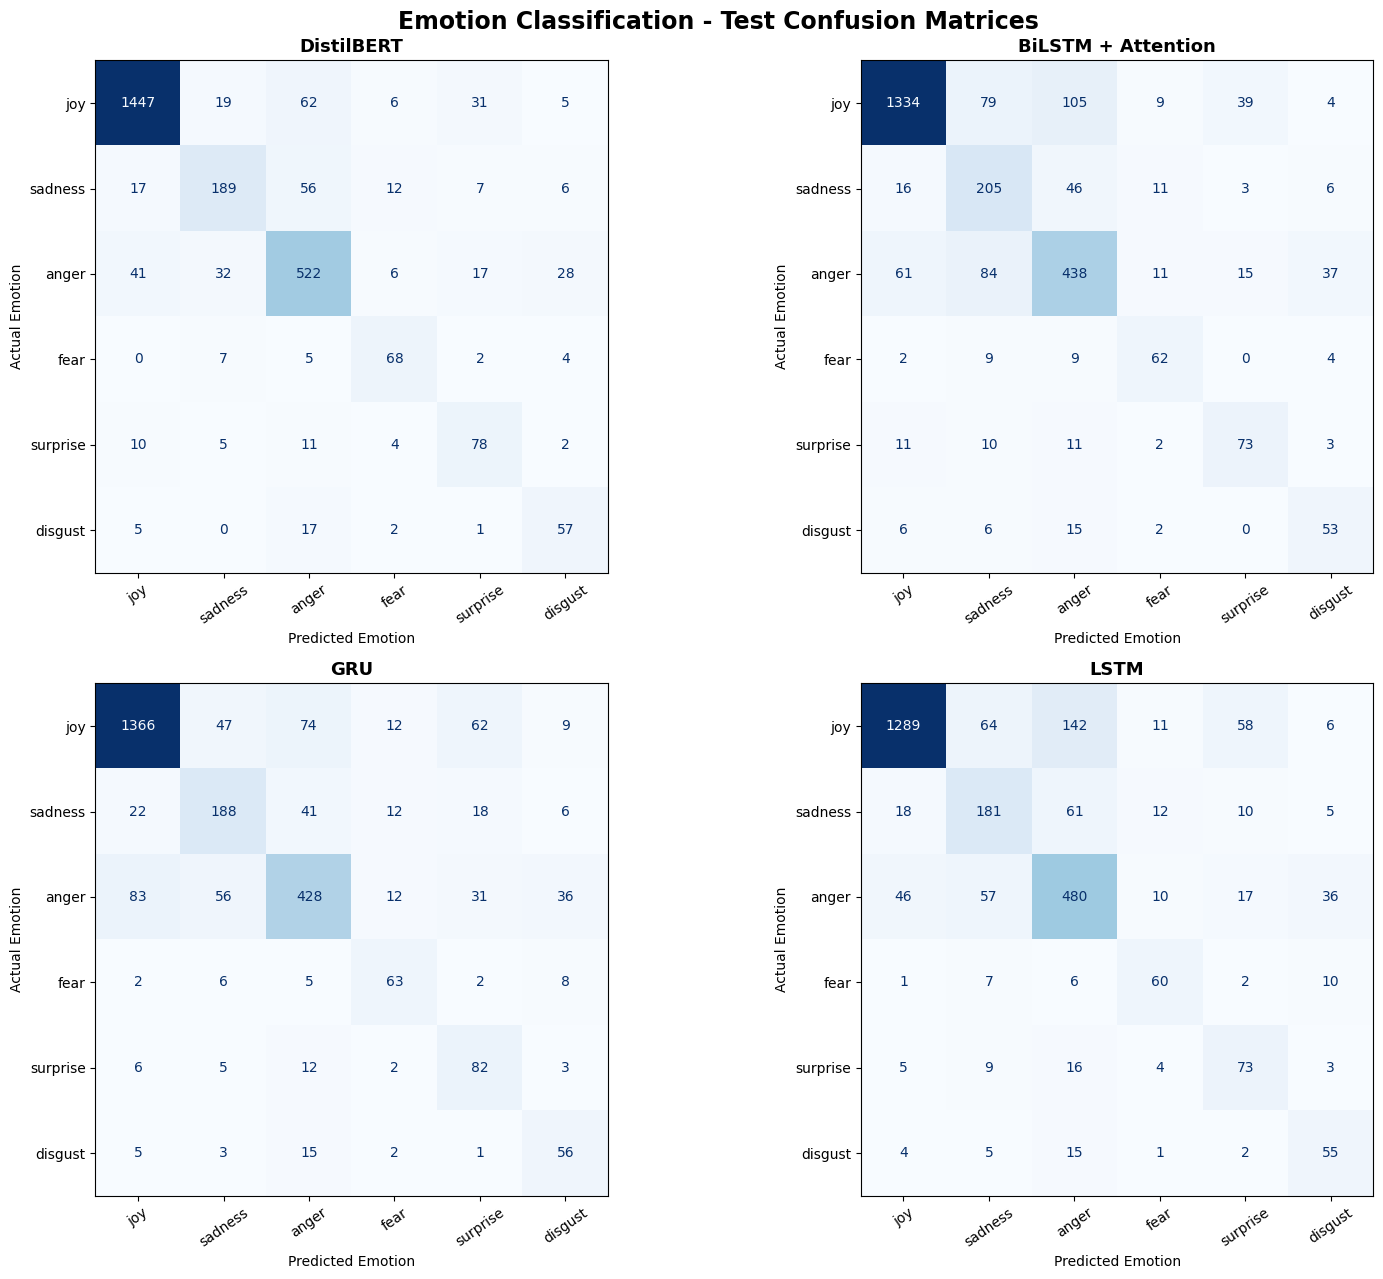

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.flatten()

model_order = [
    "DistilBERT",
    "BiLSTM + Attention",
    "GRU",
    "LSTM"
]

for ax, model_name in zip(axes, model_order):

    cm = confusion_matrix(
        test_targets,
        test_predictions[model_name],
        labels=range(NUM_CLASSES)
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=target_emotions
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(model_name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Emotion")
    ax.set_ylabel("Actual Emotion")
    ax.tick_params(axis="x", rotation=35)

plt.suptitle(
    "Emotion Classification - Test Confusion Matrices",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [48]:
import os
import json
import torch

ARTIFACT_DIR = "/content/emotion_classification_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# 1. Save custom model checkpoints
torch.save(
    lstm_model.state_dict(),
    f"{ARTIFACT_DIR}/LSTM_best.pt"
)

torch.save(
    gru_model.state_dict(),
    f"{ARTIFACT_DIR}/GRU_best.pt"
)

torch.save(
    bilstm_attention_model.state_dict(),
    f"{ARTIFACT_DIR}/BiLSTM_Attention_best.pt"
)

# 2. Save DistilBERT model and tokenizer
bert_trainer.model.save_pretrained(
    f"{ARTIFACT_DIR}/DistilBERT"
)

transformer_tokenizer.save_pretrained(
    f"{ARTIFACT_DIR}/DistilBERT"
)

# 3. Save vocabulary and label mappings
with open(f"{ARTIFACT_DIR}/vocab.json", "w") as file:
    json.dump(vocab, file, ensure_ascii=False)

with open(f"{ARTIFACT_DIR}/label_mappings.json", "w") as file:
    json.dump({
        "target_emotions": target_emotions,
        "label2id": label2id,
        "id2label": id2label,
        "emotion_mapping": emotion_mapping
    }, file, ensure_ascii=False, indent=4)

# 4. Save preprocessing configuration
with open(f"{ARTIFACT_DIR}/config.json", "w") as file:
    json.dump({
        "max_sequence_length": MAX_SEQ_LEN,
        "embedding_dim": 100,
        "hidden_dim": 128,
        "num_classes": NUM_CLASSES,
        "transformer_name": TRANSFORMER_NAME,
        "transformer_max_length": TRANSFORMER_MAX_LENGTH,
        "pad_token": PAD_TOKEN,
        "unk_token": UNK_TOKEN
    }, file, indent=4)

print("All model artifacts saved successfully!")

print("\nSaved files:")
for root, dirs, files in os.walk(ARTIFACT_DIR):
    for name in files:
        print(os.path.relpath(os.path.join(root, name), ARTIFACT_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

All model artifacts saved successfully!

Saved files:
label_mappings.json
config.json
BiLSTM_Attention_best.pt
LSTM_best.pt
GRU_best.pt
vocab.json
DistilBERT/config.json
DistilBERT/tokenizer_config.json
DistilBERT/model.safetensors
DistilBERT/tokenizer.json


In [49]:
import shutil
import os

ZIP_PATH = "/content/Emotion_Classification_Artifacts"

shutil.make_archive(
    ZIP_PATH,
    "zip",
    ARTIFACT_DIR
)

final_zip = ZIP_PATH + ".zip"

file_size = os.path.getsize(final_zip) / (1024 ** 2)

print("ZIP created successfully!")
print(f"File: {final_zip}")
print(f"Size: {file_size:.2f} MB")

ZIP created successfully!
File: /content/Emotion_Classification_Artifacts.zip
Size: 259.24 MB


In [50]:
import random

random.seed(42)

for emotion in target_emotions:
    emotion_id = label2id[emotion]

    indices = [
        i for i, label in enumerate(final_dataset["test"]["label"])
        if label == emotion_id
    ]

    selected = random.sample(indices, min(2, len(indices)))

    print(f"\n{'='*60}")
    print(emotion.upper())
    print('='*60)

    for idx in selected:
        print(f"Index: {idx}")
        print(f"Text: {final_dataset['test'][idx]['text']}")


JOY
Index: 2301
Text: Ooh you made them?! Awesome!! I hope you enjoyed them. 5 cheeses sounds like a great decision.
Index: 441
Text: Thanks so much, I appreciate the feedback and will send it along the way.

SADNESS
Index: 97
Text: No, what’s sad is saying the same message like it’s news. He’s a copy paste machine. No original thought.
Index: 1475
Text: Crap. Absolutely missed that when typing my paragraph mountains. Fixed.

ANGER
Index: 1086
Text: No one wants the wrong person executed for a crime fool
Index: 988
Text: It's not free, though. It's ridiculously expensive.

FEAR
Index: 400
Text: I know, that's why it's a little unfortunate they don't have a test. 
Index: 331
Text: I don't know any but my own I'm afraid.

SURPRISE
Index: 2252
Text: That's a surprise from this guy.
Index: 2420
Text: Oh, grilled nuggets. Haven't really seen those at fast food places so I thought they were just the regular nuggets

DISGUST
Index: 2228
Text: That is disgusting. He should be embarrassed.
Ind

In [51]:
import torch
import numpy as np
import pandas as pd
from IPython.display import display

bert_trainer.model.eval()

selected_examples = {
    "joy": [2301, 441],
    "sadness": [97, 1475],
    "anger": [1086, 988],
    "fear": [400, 331],
    "surprise": [2252, 2420],
    "disgust": [2228, 290]
}

results = []

for emotion, indices in selected_examples.items():

    for idx in indices:

        example = final_dataset["test"][idx]
        text = example["text"]
        actual_emotion = id2label[example["label"]]

        inputs = transformer_tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=TRANSFORMER_MAX_LENGTH
        )

        inputs = {
            key: value.to(DEVICE)
            for key, value in inputs.items()
        }

        with torch.no_grad():
            logits = bert_trainer.model(**inputs).logits
            probabilities = torch.softmax(logits, dim=-1)[0]

        predicted_id = probabilities.argmax().item()
        predicted_emotion = id2label[predicted_id]
        confidence = probabilities[predicted_id].item() * 100

        results.append({
            "Text": text,
            "Actual Emotion": actual_emotion,
            "Predicted Emotion": predicted_emotion,
            "Confidence": confidence,
            "Correct": actual_emotion == predicted_emotion,
            "Probabilities": {
                emotion_name: probabilities[label2id[emotion_name]].item() * 100
                for emotion_name in target_emotions
            }
        })

results_df = pd.DataFrame(results)

display(
    results_df[
        ["Actual Emotion", "Predicted Emotion", "Confidence", "Correct", "Text"]
    ].style.format({"Confidence": "{:.2f}%"})
)

print("\nCorrect Predictions:",
      results_df["Correct"].sum(), "/", len(results_df))

print("Accuracy on selected examples:",
      f"{results_df['Correct'].mean() * 100:.2f}%")

,Actual Emotion,Predicted Emotion,Confidence,Correct,Text
0,joy,joy,99.07%,True,Ooh you made them?! Awesome!! I hope you enjoyed them. 5 cheeses sounds like a great decision.
1,joy,joy,99.15%,True,"Thanks so much, I appreciate the feedback and will send it along the way."
2,sadness,sadness,96.18%,True,"No, what’s sad is saying the same message like it’s news. He’s a copy paste machine. No original thought."
3,sadness,anger,53.41%,False,Crap. Absolutely missed that when typing my paragraph mountains. Fixed.
4,anger,anger,97.26%,True,No one wants the wrong person executed for a crime fool
5,anger,anger,80.29%,True,"It's not free, though. It's ridiculously expensive."
6,fear,sadness,90.95%,False,"I know, that's why it's a little unfortunate they don't have a test."
7,fear,fear,99.24%,True,I don't know any but my own I'm afraid.
8,surprise,surprise,98.95%,True,That's a surprise from this guy.
9,surprise,surprise,96.50%,True,"Oh, grilled nuggets. Haven't really seen those at fast food places so I thought they were just the regular nuggets"



Correct Predictions: 10 / 12
Accuracy on selected examples: 83.33%


In [52]:
import torch
import pandas as pd
from IPython.display import display

bert_trainer.model.eval()

test_texts = final_dataset["test"]["text"]
test_labels = final_dataset["test"]["label"]

best_examples = {emotion: None for emotion in target_emotions}
batch_size = 32

for start in range(0, len(test_texts), batch_size):

    batch_texts = test_texts[start:start + batch_size]
    batch_labels = test_labels[start:start + batch_size]

    inputs = transformer_tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=TRANSFORMER_MAX_LENGTH,
        return_tensors="pt"
    )

    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    with torch.no_grad():
        logits = bert_trainer.model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)

    predictions = probabilities.argmax(dim=-1)
    confidences = probabilities.max(dim=-1).values

    for i in range(len(batch_texts)):

        actual_id = batch_labels[i]
        predicted_id = predictions[i].item()

        if actual_id != predicted_id:
            continue

        emotion = id2label[actual_id]
        confidence = confidences[i].item()

        if (
            best_examples[emotion] is None
            or confidence > best_examples[emotion]["Confidence"]
        ):
            best_examples[emotion] = {
                "Emotion": emotion,
                "Confidence": confidence,
                "Text": batch_texts[i]
            }

selected_df = pd.DataFrame([
    best_examples[e]
    for e in target_emotions
    if best_examples[e] is not None
])

selected_df["Confidence"] = selected_df["Confidence"] * 100

display(
    selected_df.style.format({"Confidence": "{:.2f}%"})
)

print(f"\nSelected examples: {len(selected_df)} / 6")

,Emotion,Confidence,Text
0,joy,99.24%,What a wonderful story! Thank you so much for sharing that just made me smile .
1,sadness,98.39%,I’m so sorry 🤪
2,anger,97.49%,Do not use logic dude. Not cool.
3,fear,99.24%,I don't know any but my own I'm afraid.
4,surprise,99.07%,I’m surprised by how quickly they were able to get a graphic for Kent.
5,disgust,98.60%,People are disgusting and insane.



Selected examples: 6 / 6


In [55]:
import gradio as gr
import torch
import random

bert_trainer.model.eval()

# Collect examples from all six emotions
all_examples = []

for idx, example in enumerate(final_dataset["test"]):
    all_examples.append({
        "text": example["text"],
        "index": idx
    })

# Select a balanced sample from all emotions
balanced_examples = []

for emotion in target_emotions:
    emotion_items = [
        item for item in all_examples
        if id2label[final_dataset["test"][item["index"]]["label"]] == emotion
    ]

    balanced_examples.extend(emotion_items[:20])

random.seed(42)
random.shuffle(balanced_examples)

sentence_choices = [
    f"Example {item['index']} | {item['text']}"
    for item in balanced_examples
]


def predict_emotion(text):

    if not text or not text.strip():
        return "Please select or enter a sentence.", {}

    inputs = transformer_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=TRANSFORMER_MAX_LENGTH
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        logits = bert_trainer.model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0]

    scores = {
        emotion: float(probabilities[label2id[emotion]].item())
        for emotion in target_emotions
    }

    predicted = max(scores, key=scores.get)

    return predicted.upper(), scores


def analyze_selected_sentence(selected):

    if not selected:
        return "Please select a sentence.", {}

    text = selected.split(" | ", 1)[1]

    return predict_emotion(text)


custom_css = """
.gradio-container {
    max-width: 1050px !important;
    margin: auto !important;
}
#main-title {
    text-align: center;
}
#subtitle {
    text-align: center;
    color: #64748b;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(),
    css=custom_css,
    title="Emotion Classification Studio"
) as demo:

    gr.Markdown(
        """
        # Emotion Classification Studio
        <div id="subtitle">
        AI-Powered Text Emotion Detection using DistilBERT
        </div>
        """
    )

    gr.Markdown("## Explore and Analyze Emotions")

    input_mode = gr.Radio(
        choices=["Dataset Examples", "Custom Text"],
        value="Dataset Examples",
        label="Choose Input Method"
    )

    with gr.Group(visible=True) as dataset_section:

        sentence_choice = gr.Dropdown(
            choices=sentence_choices,
            label="Choose a Sentence from the Test Dataset",
            value=None,
            interactive=True
        )

        dataset_analyze = gr.Button(
            "Analyze Sentence",
            variant="primary"
        )

    with gr.Group(visible=False) as custom_section:

        custom_input = gr.Textbox(
            label="Enter Your Text",
            placeholder="Type your sentence here...",
            lines=4
        )

        custom_analyze = gr.Button(
            "Analyze Text",
            variant="primary"
        )

    prediction_output = gr.Textbox(
        label="Predicted Emotion",
        interactive=False
    )

    confidence_output = gr.Label(
        label="Confidence Scores — All 6 Emotions",
        num_top_classes=6
    )

    def switch_mode(mode):
        return (
            gr.update(visible=(mode == "Dataset Examples")),
            gr.update(visible=(mode == "Custom Text"))
        )

    input_mode.change(
        fn=switch_mode,
        inputs=input_mode,
        outputs=[dataset_section, custom_section]
    )

    dataset_analyze.click(
        fn=analyze_selected_sentence,
        inputs=sentence_choice,
        outputs=[prediction_output, confidence_output]
    )

    custom_analyze.click(
        fn=predict_emotion,
        inputs=custom_input,
        outputs=[prediction_output, confidence_output]
    )

    gr.Markdown(
        """
        ---
        **Model:** DistilBERT
        **Dataset:** GoEmotions
        **Classes:** Joy · Sadness · Anger · Fear · Surprise · Disgust
        """
    )

demo.launch(share=True)

/tmp/ipykernel_502/2118766396.py:91: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3d53df93c76f1630ac.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
